In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Load the prepared order-level dataset
df = pd.read_csv("../data/processed/orders_prepared.csv")

# Standardize column names
df.columns = df.columns.str.strip()

# Convert lead time to numeric
df["Shipping Lead Time"] = pd.to_numeric(
    df["Shipping Lead Time"], errors="coerce"
)

# Validate required geographic and shipment columns
required_columns = [
    "Order Key",
    "Factory",
    "Region",
    "State/Province",
    "Ship Mode",
    "Shipping Lead Time"
]

missing_columns = [
    col for col in required_columns if col not in df.columns
]

print("Dataset shape:", df.shape)
print("Missing required columns:", missing_columns)

if not missing_columns:
    print("Unique orders:", df["Order Key"].nunique())
    print("Unique regions:", df["Region"].nunique())
    print("Unique states:", df["State/Province"].nunique())
    print("Missing regions:", df["Region"].isna().sum())
    print("Missing states:", df["State/Province"].isna().sum())
    print(
        "Missing lead times:",
        df["Shipping Lead Time"].isna().sum()
    )

    display(
        df[
            ["Region", "State/Province", "Order Key",
             "Shipping Lead Time"]
        ].head()
    )


Dataset shape: (10194, 36)
Missing required columns: []
Unique orders: 5111
Unique regions: 4
Unique states: 59
Missing regions: 0
Missing states: 0
Missing lead times: 0


,Region,State/Province,Order Key,Shipping Lead Time
0,Interior,Texas,US-2021-103800,909
1,Interior,Illinois,US-2021-112326,909
2,Interior,Illinois,US-2021-112326,909
3,Interior,Illinois,US-2021-112326,909
4,Atlantic,Pennsylvania,US-2021-141817,912


In [2]:

# Region-level shipping performance aggregation

# Create a unique shipment identifier
df["Shipment_ID"] = (
    df["Order Key"].astype(str)
    + "_"
    + df["Factory"].astype(str)
)

# Aggregate by geographic region
region_summary = (
    df.groupby("Region")
    .agg(
        Total_Shipments=("Shipment_ID", "nunique"),
        Mean_Lead_Time=("Shipping Lead Time", "mean"),
        Median_Lead_Time=("Shipping Lead Time", "median"),
        Std_Lead_Time=("Shipping Lead Time", "std"),
        Min_Lead_Time=("Shipping Lead Time", "min"),
        Max_Lead_Time=("Shipping Lead Time", "max")
    )
    .reset_index()
)

# Calculate coefficient of variation
region_summary["Lead_Time_CV_Percent"] = (
    region_summary["Std_Lead_Time"]
    / region_summary["Mean_Lead_Time"].replace(0, np.nan)
) * 100

# Round numerical values
numeric_cols = region_summary.select_dtypes(
    include="number"
).columns

region_summary[numeric_cols] = (
    region_summary[numeric_cols].round(2)
)

# Rank regions by highest average recorded lead time
region_summary = region_summary.sort_values(
    "Mean_Lead_Time",
    ascending=False
).reset_index(drop=True)

print("Total regions analyzed:", len(region_summary))
print("\nRegion-level shipping performance:")
display(region_summary)


Total regions analyzed: 4

Region-level shipping performance:


,Region,Total_Shipments,Mean_Lead_Time,Median_Lead_Time,Std_Lead_Time,Min_Lead_Time,Max_Lead_Time,Lead_Time_CV_Percent
0,Interior,1606,1323.09,1274.0,262.69,904,1642,19.85
1,Atlantic,2036,1322.75,1274.0,256.54,904,1642,19.39
2,Pacific,2216,1322.19,1274.0,266.47,904,1642,20.15
3,Gulf,1100,1311.37,1274.0,264.73,904,1642,20.19


In [3]:

# Define exploratory thresholds using regional medians
volume_threshold = region_summary["Total_Shipments"].median()
lead_time_threshold = region_summary["Mean_Lead_Time"].median()

region_summary["Volume_Level"] = np.where(
    region_summary["Total_Shipments"] >= volume_threshold,
    "High Volume",
    "Low Volume"
)

region_summary["Lead_Time_Level"] = np.where(
    region_summary["Mean_Lead_Time"] >= lead_time_threshold,
    "High Recorded Lead Time",
    "Low Recorded Lead Time"
)

def classify_region(row):
    if (
        row["Volume_Level"] == "High Volume"
        and row["Lead_Time_Level"] == "High Recorded Lead Time"
    ):
        return "Priority Bottleneck Candidate"
    elif row["Volume_Level"] == "High Volume":
        return "High Volume - Lower Lead Time"
    elif row["Lead_Time_Level"] == "High Recorded Lead Time":
        return "Investigate - Lower Volume"
    else:
        return "Lower Immediate Priority"

region_summary["Bottleneck_Category"] = region_summary.apply(
    classify_region, axis=1
)

print("Regional shipment threshold:", volume_threshold)
print("Regional mean lead-time threshold:", round(lead_time_threshold, 2))

display(
    region_summary[
        [
            "Region",
            "Total_Shipments",
            "Mean_Lead_Time",
            "Volume_Level",
            "Lead_Time_Level",
            "Bottleneck_Category"
        ]
    ].sort_values("Total_Shipments", ascending=False)
)


Regional shipment threshold: 1821.0
Regional mean lead-time threshold: 1322.47


,Region,Total_Shipments,Mean_Lead_Time,Volume_Level,Lead_Time_Level,Bottleneck_Category
2,Pacific,2216,1322.19,High Volume,Low Recorded Lead Time,High Volume - Lower Lead Time
1,Atlantic,2036,1322.75,High Volume,High Recorded Lead Time,Priority Bottleneck Candidate
0,Interior,1606,1323.09,Low Volume,High Recorded Lead Time,Investigate - Lower Volume
3,Gulf,1100,1311.37,Low Volume,Low Recorded Lead Time,Lower Immediate Priority



## Regional Bottleneck Analysis — Key Findings

- **Atlantic - Priority Bottleneck Candidate:** Handles 2,036 shipments and has a mean recorded lead time of 1,322.75 days, placing it above both median thresholds for shipment volume and recorded lead time.

- **Pacific - High Volume, Lower Lead Time:** Has the highest shipment volume at 2,216 shipments, but its mean recorded lead time is slightly below the regional median threshold.

- **Interior - Investigate:** Has a lower shipment volume of 1,606 shipments but the highest mean recorded lead time at 1,323.09 days, making it worth further investigation.

- **Gulf - Lower Immediate Priority:** Has the lowest shipment volume at 1,100 shipments and the lowest mean recorded lead time at 1,311.37 days.

*Note: These are exploratory, relative bottleneck classifications based on recorded data. The unusually large lead-time values require source-date validation before drawing conclusions about actual shipping efficiency or congestion.*


In [4]:

# State-level shipping performance

state_summary = (
    df.groupby(["Region", "State/Province"])
    .agg(
        Total_Shipments=("Shipment_ID", "nunique"),
        Mean_Lead_Time=("Shipping Lead Time", "mean"),
        Median_Lead_Time=("Shipping Lead Time", "median"),
        Std_Lead_Time=("Shipping Lead Time", "std")
    )
    .reset_index()
)

state_summary["Lead_Time_CV_Percent"] = (
    state_summary["Std_Lead_Time"]
    / state_summary["Mean_Lead_Time"].replace(0, np.nan)
) * 100

# Round numeric metrics
numeric_cols = state_summary.select_dtypes(
    include="number"
).columns
state_summary[numeric_cols] = state_summary[numeric_cols].round(2)

# Define relative thresholds across states
volume_threshold = state_summary["Total_Shipments"].median()
lead_time_threshold = state_summary["Mean_Lead_Time"].median()

state_summary["High_Volume"] = (
    state_summary["Total_Shipments"] >= volume_threshold
)
state_summary["High_Recorded_Lead_Time"] = (
    state_summary["Mean_Lead_Time"] >= lead_time_threshold
)

state_summary["Bottleneck_Category"] = np.select(
    [
        state_summary["High_Volume"] & state_summary["High_Recorded_Lead_Time"],
        state_summary["High_Volume"],
        state_summary["High_Recorded_Lead_Time"]
    ],
    [
        "Priority Bottleneck Candidate",
        "High Volume - Lower Lead Time",
        "Investigate - Lower Volume"
    ],
    default="Lower Immediate Priority"
)

print("States analyzed:", len(state_summary))
print("Median shipment threshold:", volume_threshold)
print("Median lead-time threshold:", round(lead_time_threshold, 2))

print("\nTop 10 states by shipment volume:")
display(
    state_summary.nlargest(10, "Total_Shipments")[
        [
            "Region", "State/Province", "Total_Shipments",
            "Mean_Lead_Time", "Bottleneck_Category"
        ]
    ]
)

print("\nTop 10 states by mean recorded lead time:")
display(
    state_summary.nlargest(10, "Mean_Lead_Time")[
        [
            "Region", "State/Province", "Total_Shipments",
            "Mean_Lead_Time", "Bottleneck_Category"
        ]
    ]
)


States analyzed: 59
Median shipment threshold: 38.0
Median lead-time threshold: 1318.43

Top 10 states by shipment volume:


,Region,State/Province,Total_Shipments,Mean_Lead_Time,Bottleneck_Category
48,Pacific,California,1365,1318.43,Priority Bottleneck Candidate
9,Atlantic,New York,763,1324.49,Priority Bottleneck Candidate
43,Interior,Texas,662,1310.31,High Volume - Lower Lead Time
14,Atlantic,Pennsylvania,407,1324.20,Priority Bottleneck Candidate
31,Interior,Illinois,362,1323.15,Priority Bottleneck Candidate
57,Pacific,Washington,350,1360.66,Priority Bottleneck Candidate
12,Atlantic,Ohio,321,1325.73,Priority Bottleneck Candidate
22,Gulf,Florida,260,1311.40,High Volume - Lower Lead Time
27,Gulf,North Carolina,182,1334.88,Priority Bottleneck Candidate
36,Interior,Michigan,171,1300.56,High Volume - Lower Lead Time



Top 10 states by mean recorded lead time:


,Region,State/Province,Total_Shipments,Mean_Lead_Time,Bottleneck_Category
19,Atlantic,West Virginia,3,1638.00,Investigate - Lower Volume
40,Interior,North Dakota,3,1637.86,Investigate - Lower Volume
55,Pacific,Saskatchewan,2,1457.00,Investigate - Lower Volume
35,Interior,Manitoba,6,1455.33,Investigate - Lower Volume
33,Interior,Iowa,22,1443.90,Investigate - Lower Volume
53,Pacific,New Mexico,29,1441.84,Investigate - Lower Volume
18,Atlantic,Vermont,9,1438.91,Investigate - Lower Volume
15,Atlantic,Prince Edward Island,6,1420.30,Investigate - Lower Volume
42,Interior,South Dakota,6,1395.92,Investigate - Lower Volume
29,Gulf,Tennessee,123,1391.49,Priority Bottleneck Candidate



## State-Level Bottleneck Analysis 

- **Tennessee - Priority Bottleneck Candidate:** Records 123 shipments and a mean lead time of 1,391.49 days, making it a high-volume location with comparatively poor recorded performance.

- **West Virginia - Investigate:** Has the highest mean recorded lead time among the listed states at 1,638.00 days, but this is based on only 3 shipments.

- **North Dakota - Investigate:** Has a mean recorded lead time of 1,637.86 days across just 3 shipments, so the result may not represent typical performance.

- **Saskatchewan and Manitoba - Investigate:** Record mean lead times of 1,457.00 and 1,455.33 days, respectively, but have only 2 and 6 shipments.

- **Iowa and New Mexico - Further Review:** Have relatively high mean recorded lead times of 1,443.90 and 1,441.84 days, with 22 and 29 shipments, respectively.
**Conclusion:** Tennessee is the most actionable high-volume bottleneck candidate in this list, while states with very small shipment counts require further investigation before prioritizing operational changes.

*Note: These are exploratory findings based on recorded lead times. The unusually large values and the underlying date fields must be validated before interpreting them as actual shipping delays or congestion.*


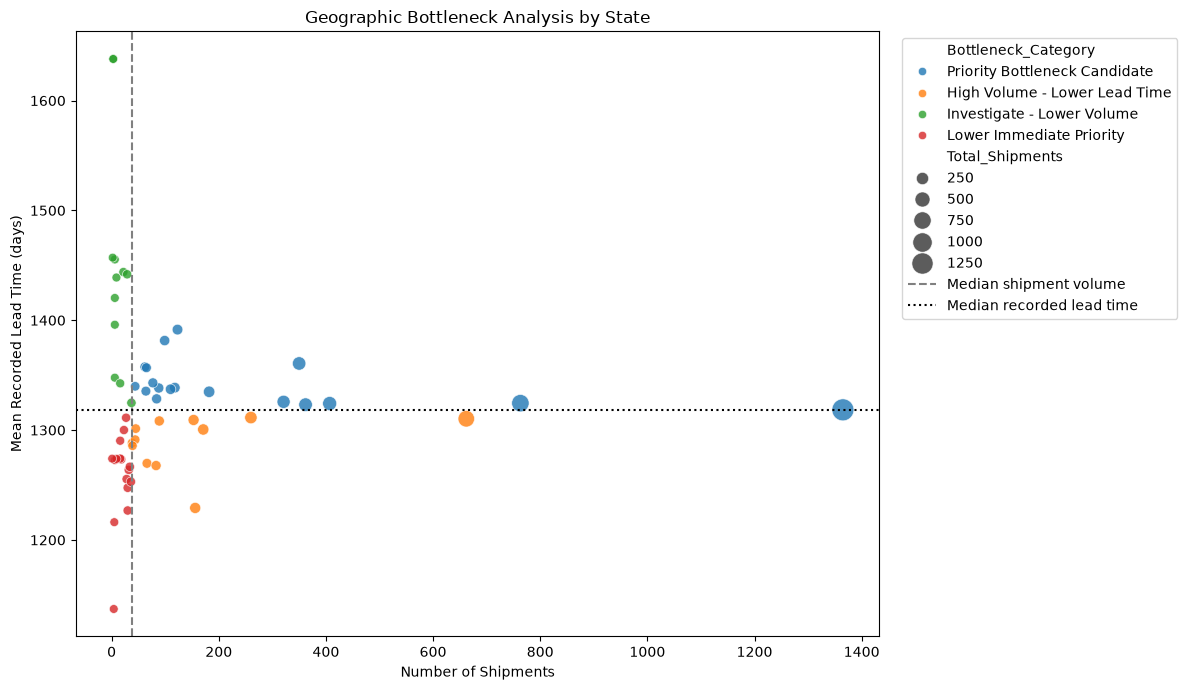

In [5]:

# State-level bottleneck visualization

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=state_summary,
    x="Total_Shipments",
    y="Mean_Lead_Time",
    hue="Bottleneck_Category",
    size="Total_Shipments",
    sizes=(40, 250),
    alpha=0.8
)

plt.axvline(
    state_summary["Total_Shipments"].median(),
    linestyle="--",
    color="gray",
    label="Median shipment volume"
)

plt.axhline(
    state_summary["Mean_Lead_Time"].median(),
    linestyle=":",
    color="black",
    label="Median recorded lead time"
)

plt.title("Geographic Bottleneck Analysis by State")
plt.xlabel("Number of Shipments")
plt.ylabel("Mean Recorded Lead Time (days)")
plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()


In [6]:

from pathlib import Path

output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

# Export regional and state-level summaries
region_path = output_dir / "regional_bottleneck_summary.csv"
state_path = output_dir / "state_bottleneck_summary.csv"

region_summary.to_csv(region_path, index=False)
state_summary.to_csv(state_path, index=False)

print("Regional summary saved to:", region_path)
print("State summary saved to:", state_path)

print("\nRegional summary shape:", region_summary.shape)
print("State summary shape:", state_summary.shape)


Regional summary saved to: ..\data\processed\regional_bottleneck_summary.csv
State summary saved to: ..\data\processed\state_bottleneck_summary.csv

Regional summary shape: (4, 11)
State summary shape: (59, 10)



## Geographic Bottleneck Analysis - Summary and Findings

The geographic bottleneck analysis examined shipping patterns across four regions and 59 states using shipment volume and recorded lead-time metrics. At the regional level, Atlantic was classified as a priority bottleneck candidate because it had both above-median shipment volume and above-median recorded lead time. Pacific handled the highest shipment volume, while Interior had the highest mean recorded lead time. At the state level, locations were classified using median-based thresholds, and a scatter plot was created to highlight high-volume, high-lead-time candidates for further investigation. Regional and state-level summaries were exported to the processed-data directory for reuse in subsequent analysis.

**Limitations:** These classifications are exploratory and relative to the dataset. The unusually large recorded lead times require validation of the underlying dates before the results can be interpreted as actual shipping delays or geographic congestion. Low-volume states should also be investigated cautiously because their averages may be sensitive to individual shipments.
